# 14 · Build a Small Real Application

**NHyDB 0.28.2 notebook series · v1**

Everything together: a small monitoring application for weather stations – data model and layout choice, NumPy batch import, indexes, SQL and QueryEngine queries, reopening, maintenance and charts. Two short additions show a document store with full-text search and a MATH_MAP grid.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* how to model an application in NHyDB (realms, shapes, layouts, address plan)
* importing time series with the NumPy batch API and reading windows back
* indexes, NHySQL and the QueryEngine on the same data
* checking and measuring the finished database
* two smaller patterns: full-text documents and a formula-addressed grid

**Recommended before:** [02](02_from_address_to_data_v1.ipynb), [08](08_addresses_are_not_indexes_v1.ipynb), [09](09_queries_and_sql_v1.ipynb), [10](10_numpy_batches_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import time

import numpy as np
import pandas as pd
from nhydb.query import Q, QueryEngine

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Background: the application

Five weather stations send one measurement per hour: temperature, humidity and a validity flag.
We want to

* store two weeks of measurements and the station master data,
* read the series of a station quickly,
* answer questions such as "average temperature per station and day",
* keep a maintenance log that can be searched by text.

### The address plan – the most important design decision

| Data | Realm | Layout | Record id `u` | Why |
|---|---|---|---|---|
| stations (name, city, altitude) | 1 `stations` | CLASSIC | station number 1 … 5 | a handful of records, read by number |
| measurements | 2 `measurements` | CLASSIC | `(station − 1) · HOURS + hour + 1` | each station is one **contiguous** `u` range → one NumPy window per station |
| maintenance notes | 3 `log` | CLASSIC + full-text index | note number | searched by words, not by address |

In NHyDB the record id is not a counter handed out by the database – **you compute it**. A good
formula puts what is read together next to each other.

## 1 · Schema and master data

In [2]:
# ▶ Try it: change the size of the data set
STATIONS = {1: ("Harbour", "Hamburg", 8), 2: ("Summit", "Zugspitze", 2962), 3: ("Vineyard", "Würzburg", 177),
            4: ("Forest", "Freiburg", 278), 5: ("Lakeside", "Konstanz", 405)}
DAYS = 14
HOURS = DAYS * 24

PATH = db_path("weather.nhydb")
db = nhydb.create(PATH)
db.create_realm(1, "stations")
db.create_shape(1, 1, "station", [{"v": 1, "name": "name", "type": "utf8"},
                                  {"v": 2, "name": "city", "type": "utf8"},
                                  {"v": 3, "name": "altitude_m", "type": "u16"}])
db.create_classic_layout(1, 1, "stations", shape_id=1)
db.put_dense_batch(1, 1, [list(STATIONS[s]) for s in sorted(STATIONS)], shape_id=1)

db.create_realm(2, "measurements")
db.create_shape(2, 2, "sample", [{"v": 1, "name": "station", "type": "u8"},
                                 {"v": 2, "name": "day", "type": "u8"},
                                 {"v": 3, "name": "hour", "type": "u16"},
                                 {"v": 4, "name": "temp_c", "type": "f32"},
                                 {"v": 5, "name": "humidity", "type": "f32"},
                                 {"v": 6, "name": "valid", "type": "bool"}])
db.create_classic_layout(2, 2, "samples", shape_id=2)
db.commit()
print("realms:", {r: v["name"] for r, v in db.realms.items()})

realms: {1: 'stations', 2: 'measurements'}


## 2 · Batch import with NumPy

**Question:** How do we bring 1,680 measurements in efficiently?

▶ **Run it:** synthetic but realistic data – a daily cycle, a cooler summit, some noise, about
1 % invalid values. One `put_numpy_batch` call per station writes all its hours at once; the loop
over the rows runs inside the Rust engine.

In [3]:
rng = np.random.default_rng(42)
hour = np.arange(HOURS, dtype=np.uint16)


def first_u(station):
    return (station - 1) * HOURS + 1                 # the address plan from the table above


t0 = time.perf_counter()
for s, (_, _, altitude) in STATIONS.items():
    temp = (14 - altitude / 160 + 6 * np.sin((hour % 24 - 9) / 24 * 2 * np.pi)
            + 2 * np.sin(hour / HOURS * 2 * np.pi) + rng.normal(0, 0.6, HOURS))
    humidity = np.clip(70 - 2.5 * (temp - temp.mean()) + rng.normal(0, 4, HOURS), 15, 100)
    db.put_numpy_batch(2, first_u(s), {
        "station": np.full(HOURS, s, dtype=np.uint8),
        "day": (hour // 24 + 1).astype(np.uint8),
        "hour": hour,
        "temp_c": temp.astype(np.float32),
        "humidity": humidity.astype(np.float32),
        "valid": rng.random(HOURS) > 0.01,
    })
db.commit()
seconds = time.perf_counter() - t0
total = HOURS * len(STATIONS)
print(f"{total:,} measurements written and committed in {seconds * 1000:.1f} ms")
assert db.get(2, first_u(3))["station"] == 3

1,680 measurements written and committed in 1.7 ms


## 3 · Where the data lives

Each station occupies one contiguous range of `u` in realm 2 (layer B → layer A). The figure shows
the ranges and the cell numbers `N` of the first field of the first and last record of each station.

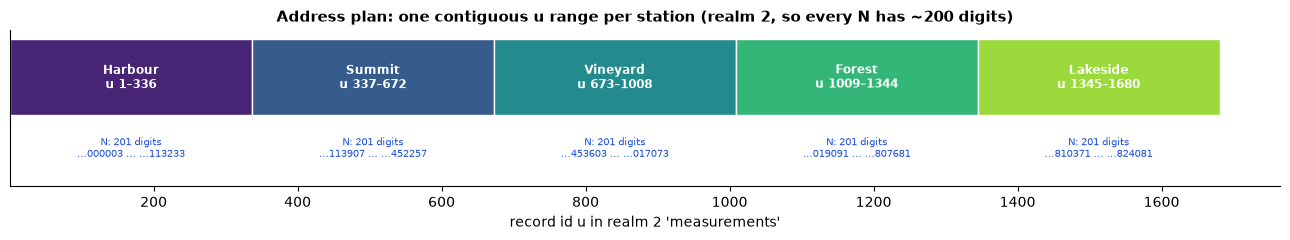

In [4]:
fig, ax = plt.subplots(figsize=(13, 2.5))
palette = plt.cm.viridis(np.linspace(0.1, 0.85, len(STATIONS)))
for i, (s, (name, city, alt)) in enumerate(STATIONS.items()):
    u0, u1 = first_u(s), first_u(s) + HOURS - 1
    ax.barh(0, u1 - u0 + 1, left=u0 - 0.5, color=palette[i], edgecolor="white")
    n0, n1 = nhydb.dynadron_n(2, u0, 1, "NL"), nhydb.dynadron_n(2, u1, 1, "NL")
    ax.text((u0 + u1) / 2, 0, f"{name}\nu {u0}–{u1}", ha="center", va="center", color="white", fontsize=8.5,
            fontweight="bold")
    ax.text((u0 + u1) / 2, -0.62, f"N: {len(str(n0))} digits\n…{str(n0)[-6:]} … …{str(n1)[-6:]}",
            ha="center", va="top", fontsize=7, color=COLORS["A"])
ax.set_ylim(-1.15, 0.5)
ax.set_yticks([])
ax.set_xlabel("record id u in realm 2 'measurements'")
ax.set_title("Address plan: one contiguous u range per station (realm 2, so every N has ~200 digits)")
plt.tight_layout()
plt.show()

**What happened?** Realm 2 starts at the global position `10^100 + 1`, so every number `N` in it
has about 200 digits (notebook 07) – nobody has to care: the application only uses `u`. Because
each station is one block of `u`, its series is one `read_numpy` call.

## 4 · Reading a series and answering questions

**Question:** How do we get the data back – as arrays, as aggregates, as filtered lists?

In [5]:
# a) the whole series of one station as NumPy columns (one call)
series = {s: db.read_numpy(2, first_u(s), HOURS, ["hour", "temp_c", "humidity", "valid"]) for s in STATIONS}
assert all(series[s]["_present"].all() for s in STATIONS)

# b) an index on 'station' and NHySQL aggregates
db.create_index(1, 2, "by_station", "station")
db.build_indexes(commit=True)
per_station = db.sql("SELECT station, COUNT(*) AS n, AVG(temp_c) AS mean, MIN(temp_c) AS lo, "
                     "MAX(temp_c) AS hi FROM samples WHERE valid = ? GROUP BY station ORDER BY station", [True])
table = pd.DataFrame(per_station["rows"])
table.insert(1, "name", [STATIONS[s][0] for s in table["station"]])
print(table.round(2).to_string(index=False))

# c) the QueryEngine: how many hot hours (> 20 °C) per station?
q = QueryEngine(db)
hot = q.execute((Q.field("temp_c") > 20) & (Q.field("valid") == True), realm=2,
                aggregate={"hours": ("count", "*")}, group_by=["station"])
print("\nhot hours:", {STATIONS[r["station"]][0]: r["hours"] for r in hot["rows"]})
print("plan for 'station = 2':", q.explain(Q.field("station") == 2, realm=2)["plan"]["access"])

 station     name   n  mean     lo    hi
       1  Harbour 330 16.06   7.79 22.15
       2   Summit 335 -2.37 -11.06  4.18
       3 Vineyard 333 15.08   6.02 21.39
       4   Forest 335 14.44   5.48 21.00
       5 Lakeside 333 13.68   5.09 20.63

hot hours: {'Harbour': 40, 'Vineyard': 20, 'Forest': 12, 'Lakeside': 1}
plan for 'station = 2': VALUE_INDEX


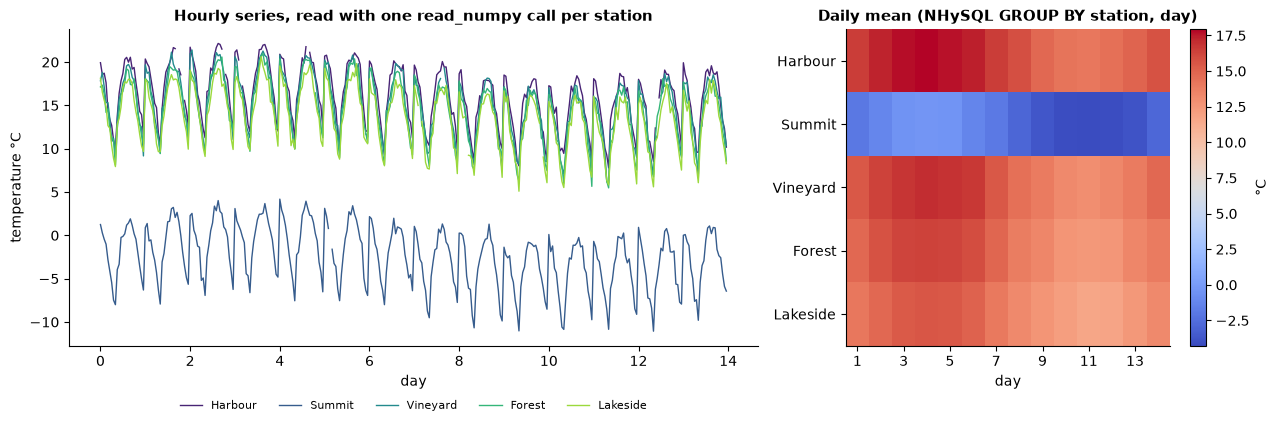

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.7, 1]})
for i, s in enumerate(STATIONS):
    d = series[s]
    t = np.where(d["valid"], d["temp_c"], np.nan)
    ax1.plot(d["hour"] / 24, t, color=palette[i], lw=1, label=STATIONS[s][0])
ax1.set_xlabel("day")
ax1.set_ylabel("temperature °C")
ax1.set_title("Hourly series, read with one read_numpy call per station")
ax1.legend(frameon=False, ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14))

daily = pd.DataFrame(db.sql("SELECT station, day, AVG(temp_c) AS mean FROM samples WHERE valid = ? "
                            "GROUP BY station, day ORDER BY station, day", [True])["rows"])
grid = daily.pivot(index="station", columns="day", values="mean")
im = ax2.imshow(grid.values, aspect="auto", cmap="coolwarm")
ax2.set_yticks(range(len(grid.index)))
ax2.set_yticklabels([STATIONS[s][0] for s in grid.index])
ax2.set_xticks(range(0, DAYS, 2))
ax2.set_xticklabels(grid.columns[::2])
ax2.set_xlabel("day")
ax2.set_title("Daily mean (NHySQL GROUP BY station, day)")
fig.colorbar(im, ax=ax2, label="°C")
plt.tight_layout()
plt.show()

## 5 · Maintenance log: full-text search

The stations get a small log. A **FULLTEXT** index ranks notes with BM25 – a typical case where
we search by *content*, not by address (notebook 08). A search returns the notes that contain
**all** search words, ranked by relevance.

In [7]:
NOTES = [
    (1, "replaced humidity sensor after salt corrosion"),
    (2, "snow on the radiation shield, temperature readings too low"),
    (2, "battery replaced, sensor recalibrated"),
    (4, "tree branch removed from the rain gauge"),
    (5, "humidity sensor drift corrected by recalibration"),
    (3, "firmware update, no data loss"),
]
db.create_realm(3, "log")
db.create_shape(3, 3, "note", [{"v": 1, "name": "station", "type": "u8"}, {"v": 2, "name": "text", "type": "utf8"}])
db.create_classic_layout(3, 3, "notes", shape_id=3)
db.put_dense_batch(3, 1, [list(n) for n in NOTES], shape_id=3)
db.create_fulltext_index(2, 3, "ft_text", "text")
db.build_indexes(commit=True)

# ▶ Try it: your own search words
SEARCH = "sensor"
hits = q.search(Q.fulltext("text", SEARCH), realm=3, select=["station", "text"], limit=5)
ranked = pd.DataFrame([{"relevance": round(h["relevance"], 3), "station": STATIONS[h["station"]][0], "note": h["text"]}
                       for h in hits["rows"]])
print(f"search: {SEARCH!r}")
ranked

search: 'sensor'


,relevance,station,note
0,0.810,Summit,"battery replaced, sensor recalibrated"
1,0.701,Harbour,replaced humidity sensor after salt corrosion
2,0.701,Lakeside,humidity sensor drift corrected by recalibration


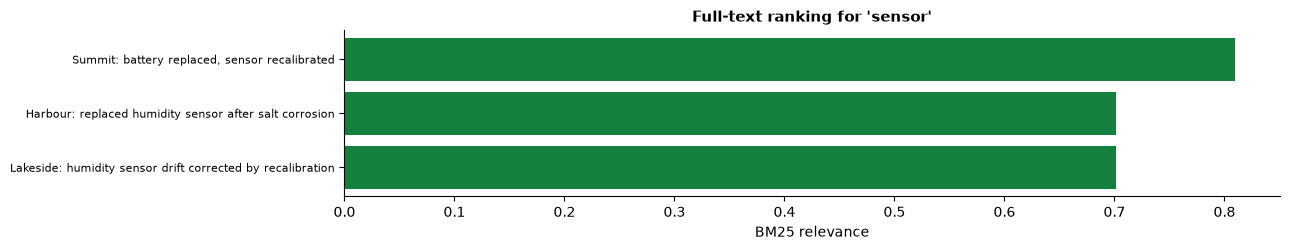

In [8]:
assert all(w in note for note in ranked["note"] for w in SEARCH.split())
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.barh(range(len(ranked))[::-1], ranked["relevance"], color=COLORS["B"])
ax.set_yticks(range(len(ranked))[::-1])
ax.set_yticklabels([f"{r.station}: {r.note}" for r in ranked.itertuples()], fontsize=8)
ax.set_xlabel("BM25 relevance")
ax.set_title(f"Full-text ranking for {SEARCH!r}")
plt.tight_layout()
plt.show()

## 6 · Close, reopen, check

The application ends, a new one starts. We reopen, verify every checksum and look at what the
database consists of.

In [9]:
db.close()

with nhydb.open(PATH) as db:
    assert db.read_numpy(2, first_u(2), 3, ["temp_c"])["temp_c"].tolist() == series[2]["temp_c"][:3].tolist()
    verify = db.verify(deep=True)
    st = db.stats()
print("verify:", verify["ok"], f"– {verify['scanned_blocks']} blocks, {verify['error_count']} errors")
print("file:", st["file_size"], "| dense records:", st["storage"]["physical_dense_records"])
sizes = file_sizes(PATH)
pd.DataFrame([{"block type": k, "blocks": v["blocks"], "bytes": v["bytes"]}
              for k, v in st["storage"]["by_block_type"].items()]).set_index("block type")

verify: True – 17 blocks, 0 errors
file: 44.16 KiB | dense records: 1691


,blocks,bytes
block type,,
DATA_DENSE,7,29352
DB_CONFIG,1,104
SECONDARY_INDEX,3,648
SECONDARY_PAGE,2,5440
SYSTEM_R0_U1,4,1488


**What happened?** About 1,700 records in a few dozen kilobytes; `verify(deep=True)` checked every
block checksum. The secondary index blocks (`SECONDARY_INDEX` and the key-tree pages
`SECONDARY_PAGE`) hold the VALUE and FULLTEXT indexes.

## 7 · Addition: stations on a map grid with MATH_MAP

Each station also has a position on a coarse map grid `(x, y)`. With a MATH layout the position
**is** the address: `u = x`, `V = y`, the lane alternates like a chessboard. A lookup by
coordinates needs no index at all (notebook 05).

(5, 5): Vineyard | (1, 1): None
QueryEngine lookup of (3, 9) and (4, 1) – rows come in the order of N: [('N …000026', (4, 1), 'Lakeside'), ('N …000141', (3, 9), 'Harbour')]
physical realm of the MATH layout: 4 (realms 1–3 are taken) → every N has 201 digits


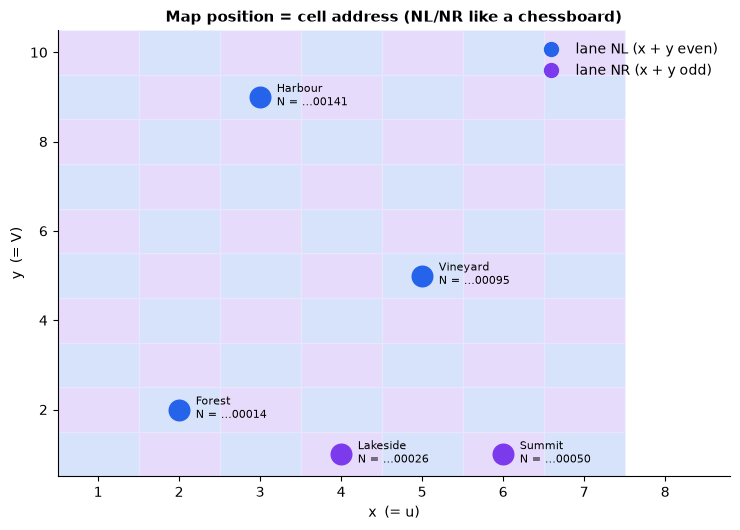

In [10]:
from nhydb.math import MathMap, MathMapLayoutSpec, dry_run

POSITIONS = {1: (3, 9), 2: (6, 1), 3: (5, 5), 4: (2, 2), 5: (4, 1)}
board = MathMap.compile("map", ("x", "y"), u="x", V="y", side="(x + y) % 2")
plan = dry_run(board, list(POSITIONS.values()))
assert plan.collisions == 0

with nhydb.open(PATH) as db:
    db.create_math_layout(MathMapLayoutSpec("map", board, 16), layout_id=10, payload_type="utf8")
    db.put_math_batch(10, [(pos, STATIONS[s][0]) for s, pos in POSITIONS.items()], commit=True)
    found = db.get_math(10, (5, 5))
    empty = db.get_math(10, (1, 1))
    r = QueryEngine(db).execute(Q.math("math_layout_inputs", layout_id=10, inputs=[(3, 9), (4, 1)]),
                                return_mode="cell")
    cells = {pos: db.get_math_cell(10, pos) for pos in POSITIONS.values()}
print("(5, 5):", found, "| (1, 1):", empty)
print("QueryEngine lookup of (3, 9) and (4, 1) – rows come in the order of N:",
      [(f"N …{row['N'][-6:]}", (row["u"], row["v"]), row["value"]) for row in r["rows"]])
print("physical realm of the MATH layout:", cells[(5, 5)]["_realm"], "(realms 1–3 are taken) → every N has",
      len(r["rows"][0]["N"]) - 1, "digits")
assert found == "Vineyard" and empty is None
assert {(row["u"], row["v"]): row["value"] for row in r["rows"]} == {(3, 9): "Harbour", (4, 1): "Lakeside"}

fig, ax = plt.subplots(figsize=(7.5, 5.4))
for x in range(1, 8):
    for y in range(1, 11):
        ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=COLORS["NR" if (x + y) % 2 else "NL"],
                               alpha=0.18, edgecolor="white"))
for (x, y), c in cells.items():
    n = nhydb.dynadron_n(c["_realm"], c["_u"], c["_v"], c["_lane"])
    ax.scatter(x, y, s=220, color=COLORS[c["_lane_name"]], zorder=3)
    ax.annotate(f"{c['value']}\nN = …{str(n)[-5:]}", (x, y), textcoords="offset points", xytext=(12, -6), fontsize=8)
ax.set_xlim(0.5, 8.8)
ax.set_ylim(0.5, 10.5)
handles = [plt.Line2D([], [], marker="o", ls="", ms=10, color=COLORS[k]) for k in ("NL", "NR")]
ax.legend(handles, ["lane NL (x + y even)", "lane NR (x + y odd)"], frameon=False, loc="upper right")
ax.set_xlabel("x  (= u)")
ax.set_ylabel("y  (= V)")
ax.set_title("Map position = cell address (NL/NR like a chessboard)")
plt.tight_layout()
plt.show()

## Your turn

**Task:** which station had the largest temperature range (max − min) on day 7? Answer with one
NHySQL query.

In [11]:
with nhydb.open(PATH) as db:
    r = db.sql("SELECT station, MAX(temp_c) AS hi, MIN(temp_c) AS lo FROM samples "
               "WHERE day = ? AND valid = ? GROUP BY station", [7, True])
ranges = {row["station"]: row["hi"] - row["lo"] for row in r["rows"]}
best = max(ranges, key=ranges.get)
print(f"largest range on day 7: {STATIONS[best][0]} ({ranges[best]:.1f} K)")
# cross-check with NumPy on the series read in section 4
check = {s: np.ptp(series[s]["temp_c"][(series[s]["hour"] // 24 == 6) & series[s]["valid"]]) for s in STATIONS}
assert max(check, key=check.get) == best

largest range on day 7: Forest (11.2 K)


## ⏩ Advanced: what to change for a real deployment

* **More data:** raise `DAYS` – the address plan stays the same; choose `HOURS` large enough for
  the whole period you want to keep per station (or put each year into its own `u` range).
* **New stations:** a new station simply gets the next `u` range – no migration.
* **Extra fields** for some records only: extensions (Cookbook section 8) – they are stored sparsely.
* **Durability:** `durability="full"` for the strongest commit on macOS; batch commits instead of one
  commit per measurement (notebook 13 measures the difference).
* **Backups:** all three files, database closed (notebook 11); keep the key file safe (notebook 12).

## Summary

* Design the address plan first: compute `u` so that data read together is contiguous.
* `put_numpy_batch` and `read_numpy` move whole columns; SQL and the QueryEngine answer questions on top.
* Content search uses indexes (VALUE, FULLTEXT); positions can be addresses directly (MATH_MAP).
* Reopen, `verify(deep=True)` and `stats()` confirm and describe the finished database.

## Where to go next

* [13 · Benchmark Lab](13_benchmark_lab_v1.ipynb) – measure the import on your machine.
* Example programs in `examples/python/` of the NHyDB repository (sensor_timeseries, document_store, math_map_grid).
* The reference notebooks in `../reference/` – every Cookbook example to run.

**Cookbook sections:** 6 (Records), 13 (Indexes), 14 (QueryEngine), 15 (NHySQL), 16 (NumPy), 18 (MATH_MAP), 25 (Applications) in the [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [12]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
